# Pruebas estadísticas de cambios en frecuencia

Este notebook toma las tablas de frecuencias generadas en el notebook anterior y evalúa si los cambios observados son estadísticamente significativos.

1. **Carga** las tablas de frecuencias de nucleótidos y aminoácidos.
2. **Reconstruye** los conteos por año a partir de las frecuencias y el número de genomas.
3. **Aplica Chi^2/Fisher** entre 2021 y 2022 para las mutaciones de interés.
4. **Aplica regresión logística** con año como variable independiente.
5. **Consolida** los resultados en tablas y gráficas.
6. **Guarda** todo en data/processed/ y results/images/.


In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import chi2_contingency, fisher_exact
import warnings

warnings.filterwarnings("ignore")


In [2]:
BASE_DIR = "/export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene"

NEXTCLADE_DIR = BASE_DIR + "/results/nextclade"
OUT_DIR = BASE_DIR + "/data/processed"
FIG_DIR = BASE_DIR + "/results/images"


print("Carpeta del repositorio:", BASE_DIR)
print("Carpeta de salida:", OUT_DIR)
print("Carpeta de figuras:", FIG_DIR)

Carpeta del repositorio: /export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene
Carpeta de salida: /export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/data/processed
Carpeta de figuras: /export/space3/users/mariosb/LCG/BIOPYTHON/analisis_var_gene/results/images


## 2. Cargar tablas de frecuencias y reconstruir conteos

Las tablas del notebook anterior están en **formato ancho** (índice = mutación, columnas = años con frecuencias). Para las pruebas estadísticas necesitamos **conteos**, así que los reconstruimos multiplicando la frecuencia por el número de genomas de cada año.

**Nota**: el número de genomas por año se toma del notebook anterior. Si no lo tienes, se puede recalcular cargando los TSV de Nextclade con los mismos filtros.

In [3]:
def load_wide_tables(out_dir):
    """
    Carga las tablas de frecuencias en formato ancho.
    """

    wide_aa = pd.read_csv(out_dir + "/nuevas_frecuencias_aa_por_anio.tsv",sep="\t",index_col=[0, 1])

    wide_nt = pd.read_csv(out_dir + "/nuevas_frecuencias_nt_por_anio.tsv",sep="\t",index_col=[0, 1])

    # ------------------------------------------------------------------------------------- Eliminar la columna max_frequency si existe
    for df in (wide_aa, wide_nt):
        if "max_frequency" in df.columns:
            df.drop(columns="max_frequency", inplace=True)

    # ------------------------------------------------------------------------------------- Asegurar que las columnas de año sean enteros
    for df in (wide_aa, wide_nt):
        df.columns = [int(c) if str(c).isdigit() else c for c in df.columns]
    return wide_aa, wide_nt


def count_genomes_by_year(nextclade_dir, years, exclude):
    """
    Cuenta genomas por año aplicando los mismos filtros del notebook anterior.
    """

    n_genomes = {}

    for year in years:
        file = nextclade_dir + f"/nextclade_{year}.tsv"

        nc = pd.read_csv(file, sep="\t")
        nc = nc[~nc["seqName"].isin(exclude)]
        n_genomes[year] = len(nc)
    return n_genomes

# ----------------------------------------------------------------------------------------- Procesamiento

years = [2020, 2021, 2022, 2023, 2024]

wide_aa, wide_nt = load_wide_tables(OUT_DIR)
n_genomes = count_genomes_by_year(NEXTCLADE_DIR, years, exclude=[])

print("wide_aa:", wide_aa.shape)
print("wide_nt:", wide_nt.shape)
print("Genomas por año:", n_genomes)

wide_aa: (1070, 5)
wide_nt: (2019, 5)
Genomas por año: {2020: 81, 2021: 80, 2022: 80, 2023: 80, 2024: 80}


## 3. Prueba 1: Chi^2 / Fisher entre dos periodos

Para cada mutación, comparamos su frecuencia entre **2021 y 2022** (transición Delta → Omicron). Construimos una tabla 2×2:

| | Con mutación | Sin mutación |
|:---|:---:|:---:|
| 2021 | a | b |
| 2022 | c | d |

Aplicamos Chi^2 si todos los valores esperados son ≥5; si no, Fisher exacto.

In [4]:
def test_two_periods(wide, n_genomes, mutation, gene, year1=2021, year2=2022):
    """
    Compara la frecuencia de una mutación entre dos años usando Chi² o Fisher.
    """


    row = wide.loc[(mutation, gene)]


    # ------------------------------------------------------------------------------------ Obtener frecuencias y tamaños de muestra
    f1 = float(row.get(year1, 0))
    f2 = float(row.get(year2, 0))

    n1 = n_genomes[year1]
    n2 = n_genomes[year2]

    # ------------------------------------------------------------------------------------ Reconstruir frecuencias absolutas
    a = int(round(f1 * n1))
    b = n1 - a
    c = int(round(f2 * n2))
    d = n2 - c

    # ------------------------------------------------------------------------------------ Tabla de contingencia
    table = np.array([[a, b], [c, d]])

    # ------------------------------------------------------------------------------------ Selección de prueba estadística

    if a + c == 0:
        p_val = 1.0
        test = "no_occurrences"

    else:
        # -------------------------------------------------------------------------------- Calcular frecuencias esperadas
        expected = (np.outer(table.sum(axis=1), table.sum(axis=0)) / table.sum())

        if (expected < 5).any():
            _, p_val = fisher_exact(table)
            test = "fisher"
        else:
            _, p_val, _, _ = chi2_contingency(table, correction=False)
            test = "chi2"


    # ------------------------------------------------------------------------------------ Resultados

    return {
        "mutation": mutation,
        "gene": gene,
        "year1": year1,
        "year2": year2,
        "freq_year1": round(f1, 4),
        "freq_year2": round(f2, 4),
        "delta": round(f2 - f1, 4),
        "test": test,
        "p_value": round(float(p_val), 6),
        "significativo": p_val < 0.05
    }

In [5]:
# ------------------------------------------------------------------------ Mutaciones de interés: las que muestran los cambios más drásticos en las tablas
mutaciones_aa = [
    ("S:T478K", "S"),
    ("ORF1a:T3255I", "ORF1a"),
    ("S:N501Y", "S"),
    ("E:T9I", "E"),
    ("M:A63T", "M"),
    ("ORF1b:I1566V", "ORF1b"),
    ("S:D796Y", "S"),
    ("S:H655Y", "S"),
    ("S:N679K", "S"),
    ("S:S477N", "S"),
]

mutaciones_nt = [
    ("A23403G", "S"),
    ("C14408T", "ORF1b"),
    ("C3037T", "ORF1a"),
    ("C22995A", "S"),
    ("C10029T", "ORF1a"),
    ("G28881A", "N"),
    ("G28882A", "N"),
    ("G28883C", "N"),
    ("T22917G", "S"),
    ("G21987A", "S"),
    ("C28311T", "ORF9b"),
    ("C28311T", "N"),
    ("C26060T", "ORF3a"),
    ("C23604A", "S"),
]

df_aa_period = pd.DataFrame([test_two_periods(wide_aa, n_genomes, m, g) for m, g in mutaciones_aa])
df_nt_period = pd.DataFrame([test_two_periods(wide_nt, n_genomes, m, g) for m, g in mutaciones_nt])

print("AA entre periodos (2021 vs 2022)")
print(df_aa_period.to_string(index=False))
print("\nNT entre periodos (2021 vs 2022)")
print(df_nt_period.to_string(index=False))

AA entre periodos (2021 vs 2022)
    mutation  gene  year1  year2  freq_year1  freq_year2  delta   test  p_value  significativo
     S:T478K     S   2021   2022      0.9250      0.9875 0.0625 fisher 0.116747          False
ORF1a:T3255I ORF1a   2021   2022      0.7125      1.0000 0.2875   chi2 0.000000           True
     S:N501Y     S   2021   2022      0.1125      0.8875 0.7750   chi2 0.000000           True
       E:T9I     E   2021   2022      0.0750      0.9000 0.8250   chi2 0.000000           True
      M:A63T     M   2021   2022      0.0750      0.9000 0.8250   chi2 0.000000           True
ORF1b:I1566V ORF1b   2021   2022      0.0750      0.9000 0.8250   chi2 0.000000           True
     S:D796Y     S   2021   2022      0.0750      0.9000 0.8250   chi2 0.000000           True
     S:H655Y     S   2021   2022      0.0750      0.9000 0.8250   chi2 0.000000           True
     S:N679K     S   2021   2022      0.0750      0.9000 0.8250   chi2 0.000000           True
     S:S477N     

## 4. Regresión logística (tendencia temporal)

Para cada mutación, modelamos:

mutación_presente (0/1) ~ año

El coeficiente del año indica la dirección de la tendencia:
- **Positivo y significativo** (p < 0.05): la mutación aumenta con el tiempo.
- **Negativo y significativo**: la mutación disminuye.
- **No significativo**: no hay evidencia de tendencia.

Se usa statsmodels.Logit. Si la mutación no varía (todos 0 o todos 1), se marca como no_variation.

In [6]:
def load_nextclade(year, nextclade_dir, exclude):
    """
    Carga y filtra el TSV de Nextclade de un año.

    Parámetros:
        year: Año del archivo.
        nextclade_dir: Carpeta con los TSV.
        exclude: Genomas a excluir.

    Devuelve:
        pd.DataFrame: Nextclade filtrado (QC good, sin excluidos).
    """
    path = nextclade_dir + f"/nextclade_{year}.tsv"
    nc = pd.read_csv(path, sep="\t")
    nc = nc[~nc["seqName"].isin(exclude)]
    nc = nc[nc["qc.overallStatus"] == "good"]
    return nc.reset_index(drop=True)


nc_by_year = {}
for year in years:
    nc_by_year[year] = load_nextclade(year, NEXTCLADE_DIR, exclude=[])

print("Genomas cargados por año:", {y: len(nc) for y, nc in nc_by_year.items()})

Genomas cargados por año: {2020: 80, 2021: 73, 2022: 73, 2023: 77, 2024: 80}


In [7]:
def logistic_trend(nc_by_year, mutation, gene, kind="aa"):
    """
    Ajusta una regresión logística:
    presencia_mutación -> año.
    """

    rows = []

    for year, nc in sorted(nc_by_year.items()):

        if kind == "aa":
            target = mutation

            if target.startswith(f"{gene}:"):
                target = target.split(":", 1)[1]

            target = f"{gene}:{target}"
            has = (nc["aaSubstitutions"].fillna("").str.contains(target, regex=False).astype(int))

        elif kind == "nt":
            has = (nc["substitutions"].fillna("").str.contains(mutation, regex=False).astype(int))
        else: raise ValueError("kind debe ser 'aa' o 'nt'.")

        rows.append(pd.DataFrame({"year": year,"has_mut": has}))

    if not rows:
        return {
            "mutation": mutation,
            "gene": gene,
            "coef_year": np.nan,
            "odds_ratio": np.nan,
            "p_value": np.nan,
            "n_with_mut": 0,
            "n_total": 0,
            "test": "no_data"
        }

    df = pd.concat(rows, ignore_index=True)

    n_with_mut = int(df["has_mut"].sum())
    n_total = len(df)

    if df["has_mut"].nunique() < 2:
        return {
            "mutation": mutation,
            "gene": gene,
            "coef_year": np.nan,
            "odds_ratio": np.nan,
            "p_value": np.nan,
            "n_with_mut": n_with_mut,
            "n_total": n_total,
            "test": "no_variation"
        }

    X = sm.add_constant(df["year"].astype(float))

    try:
        model = sm.Logit(df["has_mut"], X).fit(disp=0)

        coef = model.params["year"]
        p_val = model.pvalues["year"]

        return {
            "mutation": mutation,
            "gene": gene,
            "coef_year": round(float(coef), 4),
            "odds_ratio": round(float(np.exp(coef)), 4),
            "p_value": round(float(p_val), 6),
            "n_with_mut": n_with_mut,
            "n_total": n_total,
            "test": "logit"
        }

    except Exception as error:
        return {
            "mutation": mutation,
            "gene": gene,
            "coef_year": np.nan,
            "odds_ratio": np.nan,
            "p_value": np.nan,
            "n_with_mut": n_with_mut,
            "n_total": n_total,
            "test": f"error: {str(error)[:50]}"
        }

In [8]:

df_aa_trend = pd.DataFrame([logistic_trend(nc_by_year, m, g, kind="aa")for m, g in mutaciones_aa])

df_nt_trend = pd.DataFrame([logistic_trend(nc_by_year, m, g, kind="nt")for m, g in mutaciones_nt])

print("=== Tendencia AA ===")
print(df_aa_trend.to_string(index=False))

print("\n=== Tendencia NT ===")
print(df_nt_trend.to_string(index=False))


=== Tendencia AA ===
    mutation  gene  coef_year  odds_ratio  p_value  n_with_mut  n_total  test
     S:T478K     S     2.0153      7.5033      0.0         290      383 logit
ORF1a:T3255I ORF1a     1.7103      5.5309      0.0         276      383 logit
     S:N501Y     S     2.1710      8.7666      0.0         223      383 logit
       E:T9I     E     2.2806      9.7821      0.0         221      383 logit
      M:A63T     M     2.2806      9.7821      0.0         221      383 logit
ORF1b:I1566V ORF1b     2.2806      9.7821      0.0         221      383 logit
     S:D796Y     S     2.2806      9.7821      0.0         221      383 logit
     S:H655Y     S     2.2806      9.7821      0.0         221      383 logit
     S:N679K     S     2.2806      9.7821      0.0         221      383 logit
     S:S477N     S     2.2806      9.7821      0.0         221      383 logit

=== Tendencia NT ===
mutation  gene  coef_year  odds_ratio  p_value  n_with_mut  n_total  test
 A23403G     S     6.6910

## 5. Consolidación y guardado

Unimos los resultados de ambas pruebas en una sola tabla por nivel (AA y NT), con columnas claras y banderas de significancia.

In [9]:
def consolidate(period_df, trend_df):
    """
    Une los resultados de Chi^2/Fisher y regresión logística en una sola tabla.

    Parámetros:
        period_df:
            Resultados de test_two_periods.
        trend_df:
            Resultados de logistic_trend.

    Devuelve:
        pd.DataFrame:
            Tabla consolidada con p-valores, coeficientes y banderas de significancia.
    """
    merged = period_df.merge(trend_df[["mutation", "gene", "coef_year", "odds_ratio", "p_value"]],
        on=["mutation", "gene"], how="left", suffixes=("_periodos", "_tendencia")
    )
    merged["significativo_periodos"] = merged["p_value_periodos"] < 0.05
    merged["significativo_tendencia"] = merged["p_value_tendencia"] < 0.05

    # ----------------------------------------------------------------------------------------- Dirección de la tendencia
    merged["direccion"] = np.where(merged["coef_year"].isna(), "sin_datos",np.where(merged["coef_year"] > 0,
        "aumenta", np.where(merged["coef_year"] < 0, "disminuye", "sin_cambio"))
    )
    return merged


df_aa_final = consolidate(df_aa_period, df_aa_trend)
df_nt_final = consolidate(df_nt_period, df_nt_trend)

df_aa_final.to_csv(OUT_DIR + "/resultados_estadisticos_aa.tsv",sep="\t",index=False)
df_nt_final.to_csv(OUT_DIR + "/resultados_estadisticos_nt.tsv",sep="\t",index=False)

print("Guardado: resultados_estadisticos_aa.tsv")
print("Guardado: resultados_estadisticos_nt.tsv")
print("\n=== Resumen AA ===")
print(df_aa_final[["mutation", "gene", "delta", "p_value_periodos","coef_year", "odds_ratio", "p_value_tendencia","significativo_periodos","significativo_tendencia", "direccion"]].to_string(index=False))
print("\n=== Resumen NT ===")
print(df_nt_final[["mutation", "gene", "delta", "p_value_periodos","coef_year", "odds_ratio", "p_value_tendencia","significativo_periodos","significativo_tendencia", "direccion"]].to_string(index=False))

Guardado: resultados_estadisticos_aa.tsv
Guardado: resultados_estadisticos_nt.tsv

=== Resumen AA ===
    mutation  gene  delta  p_value_periodos  coef_year  odds_ratio  p_value_tendencia  significativo_periodos  significativo_tendencia direccion
     S:T478K     S 0.0625          0.116747     2.0153      7.5033                0.0                   False                     True   aumenta
ORF1a:T3255I ORF1a 0.2875          0.000000     1.7103      5.5309                0.0                    True                     True   aumenta
     S:N501Y     S 0.7750          0.000000     2.1710      8.7666                0.0                    True                     True   aumenta
       E:T9I     E 0.8250          0.000000     2.2806      9.7821                0.0                    True                     True   aumenta
      M:A63T     M 0.8250          0.000000     2.2806      9.7821                0.0                    True                     True   aumenta
ORF1b:I1566V ORF1b 0.8250   

## 6. Visualizaciones

Dos gráficas para el notebook y la presentación:

1. **Barras de delta de frecuencia** entre 2021 y 2022, coloreadas por significancia.
2. **Forest plot** de odds ratios (tendencia temporal), con intervalos de confianza.

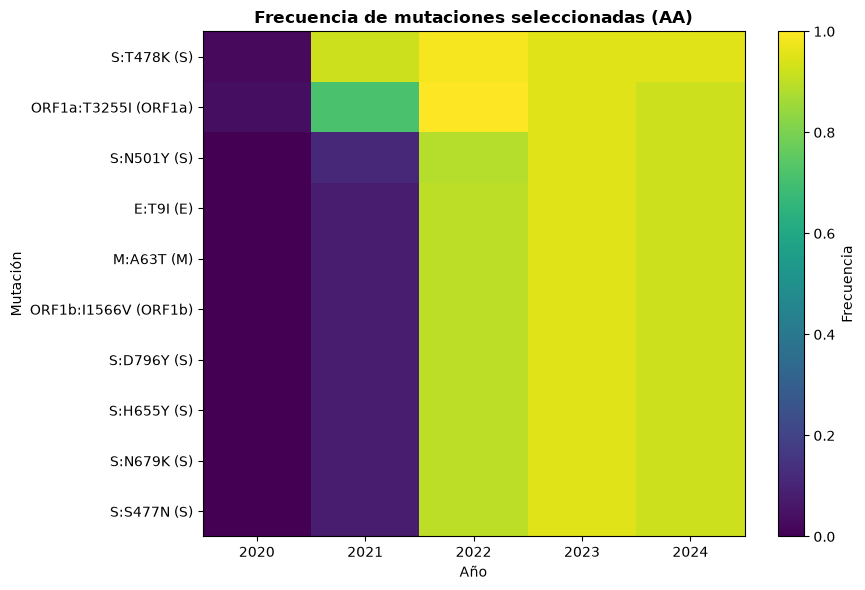

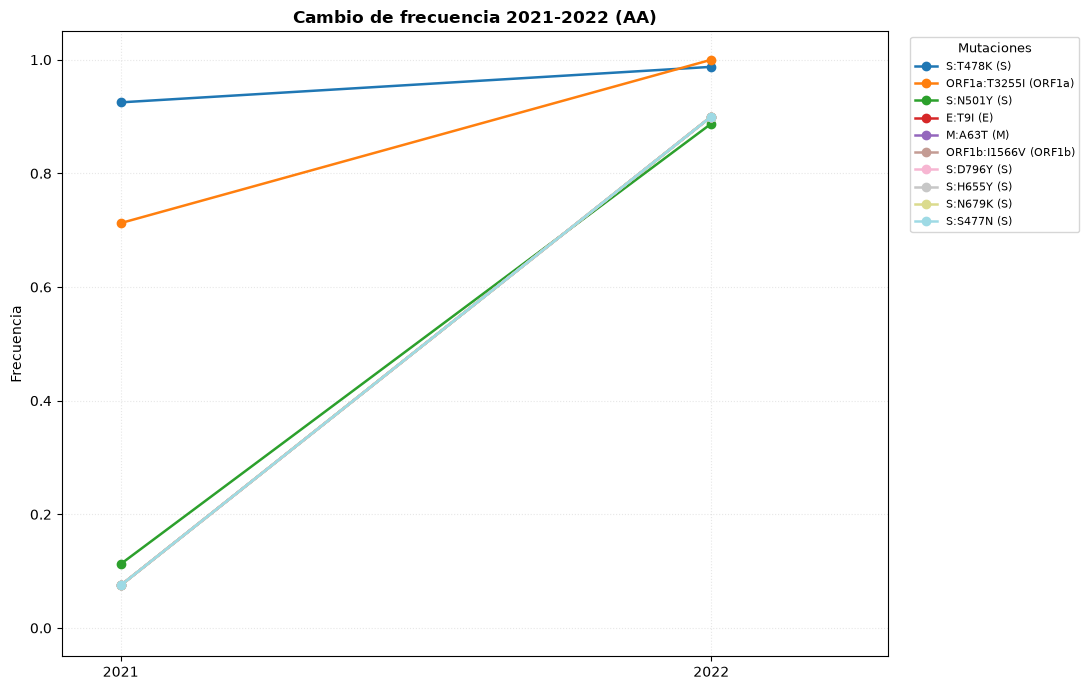

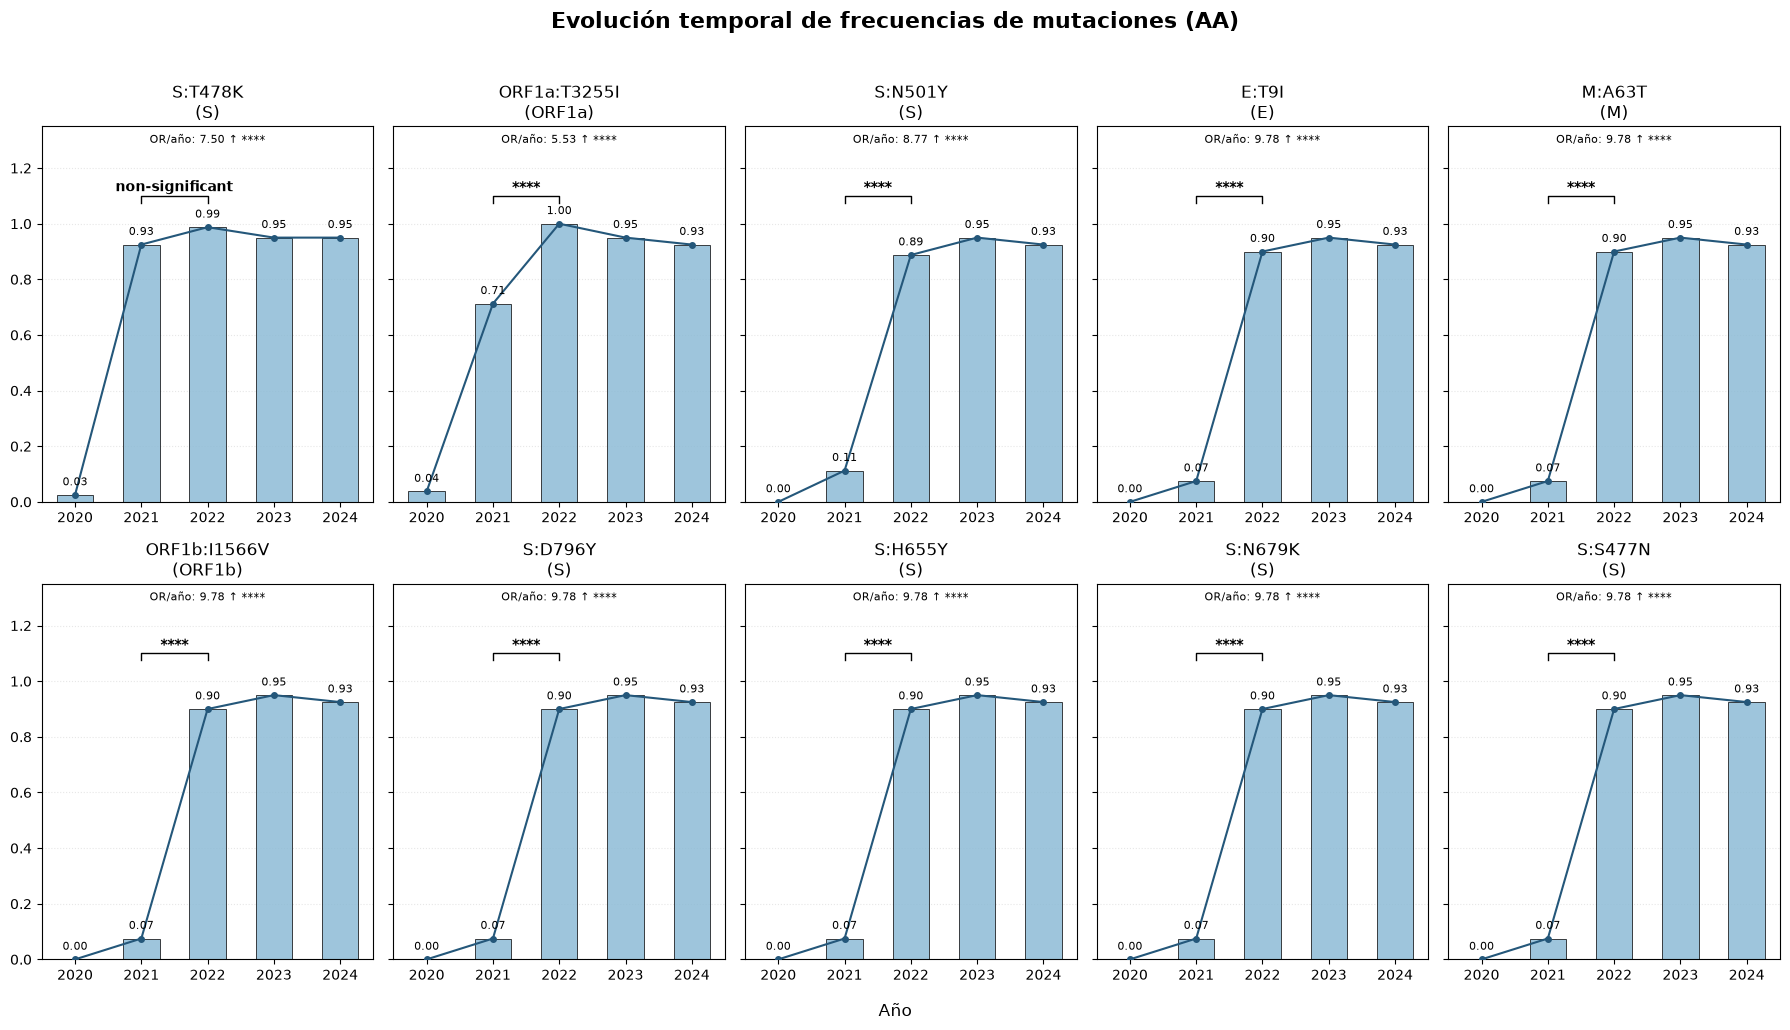

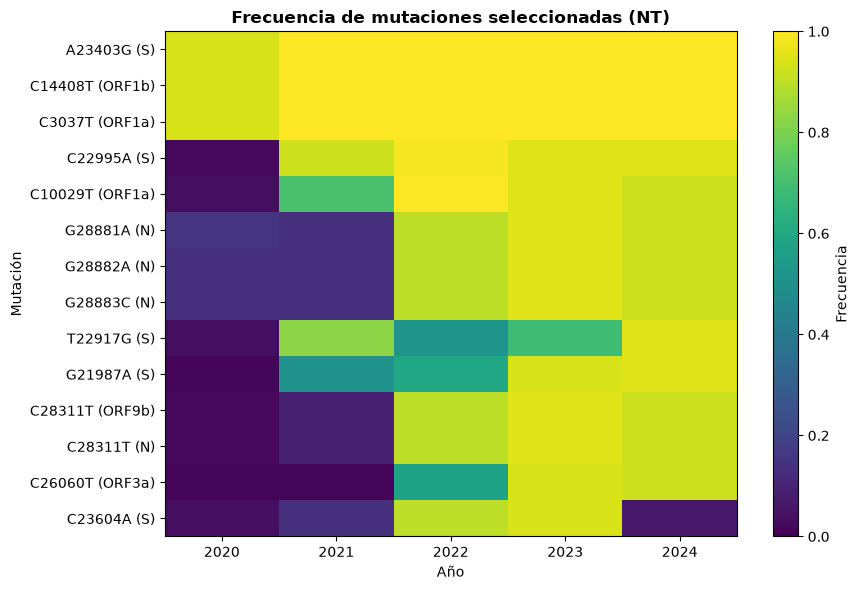

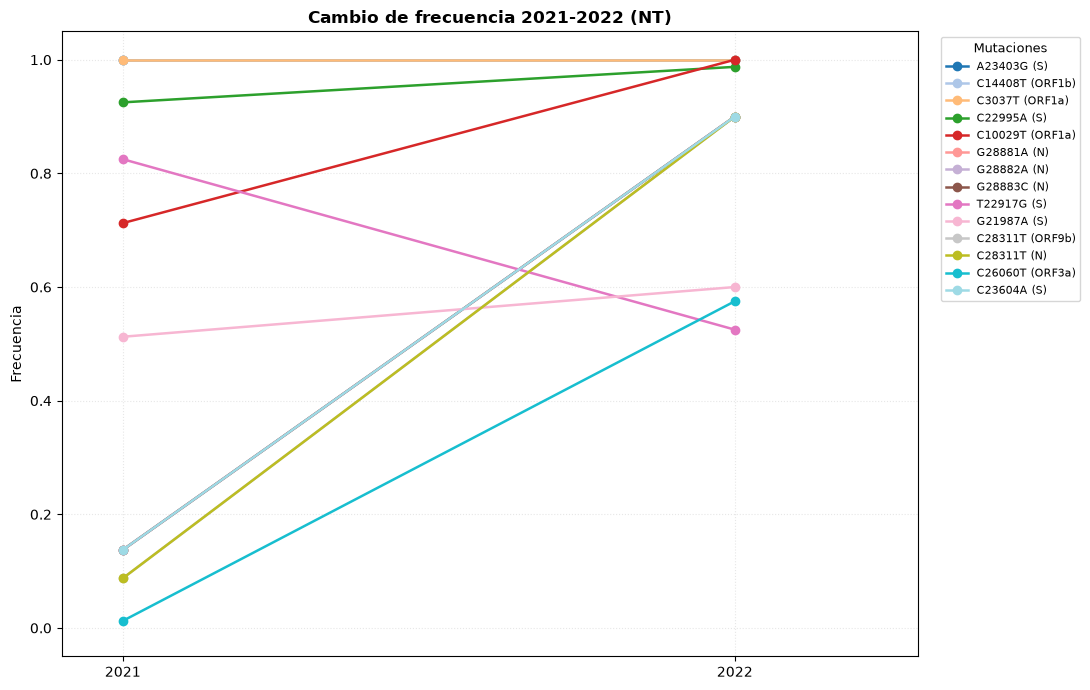

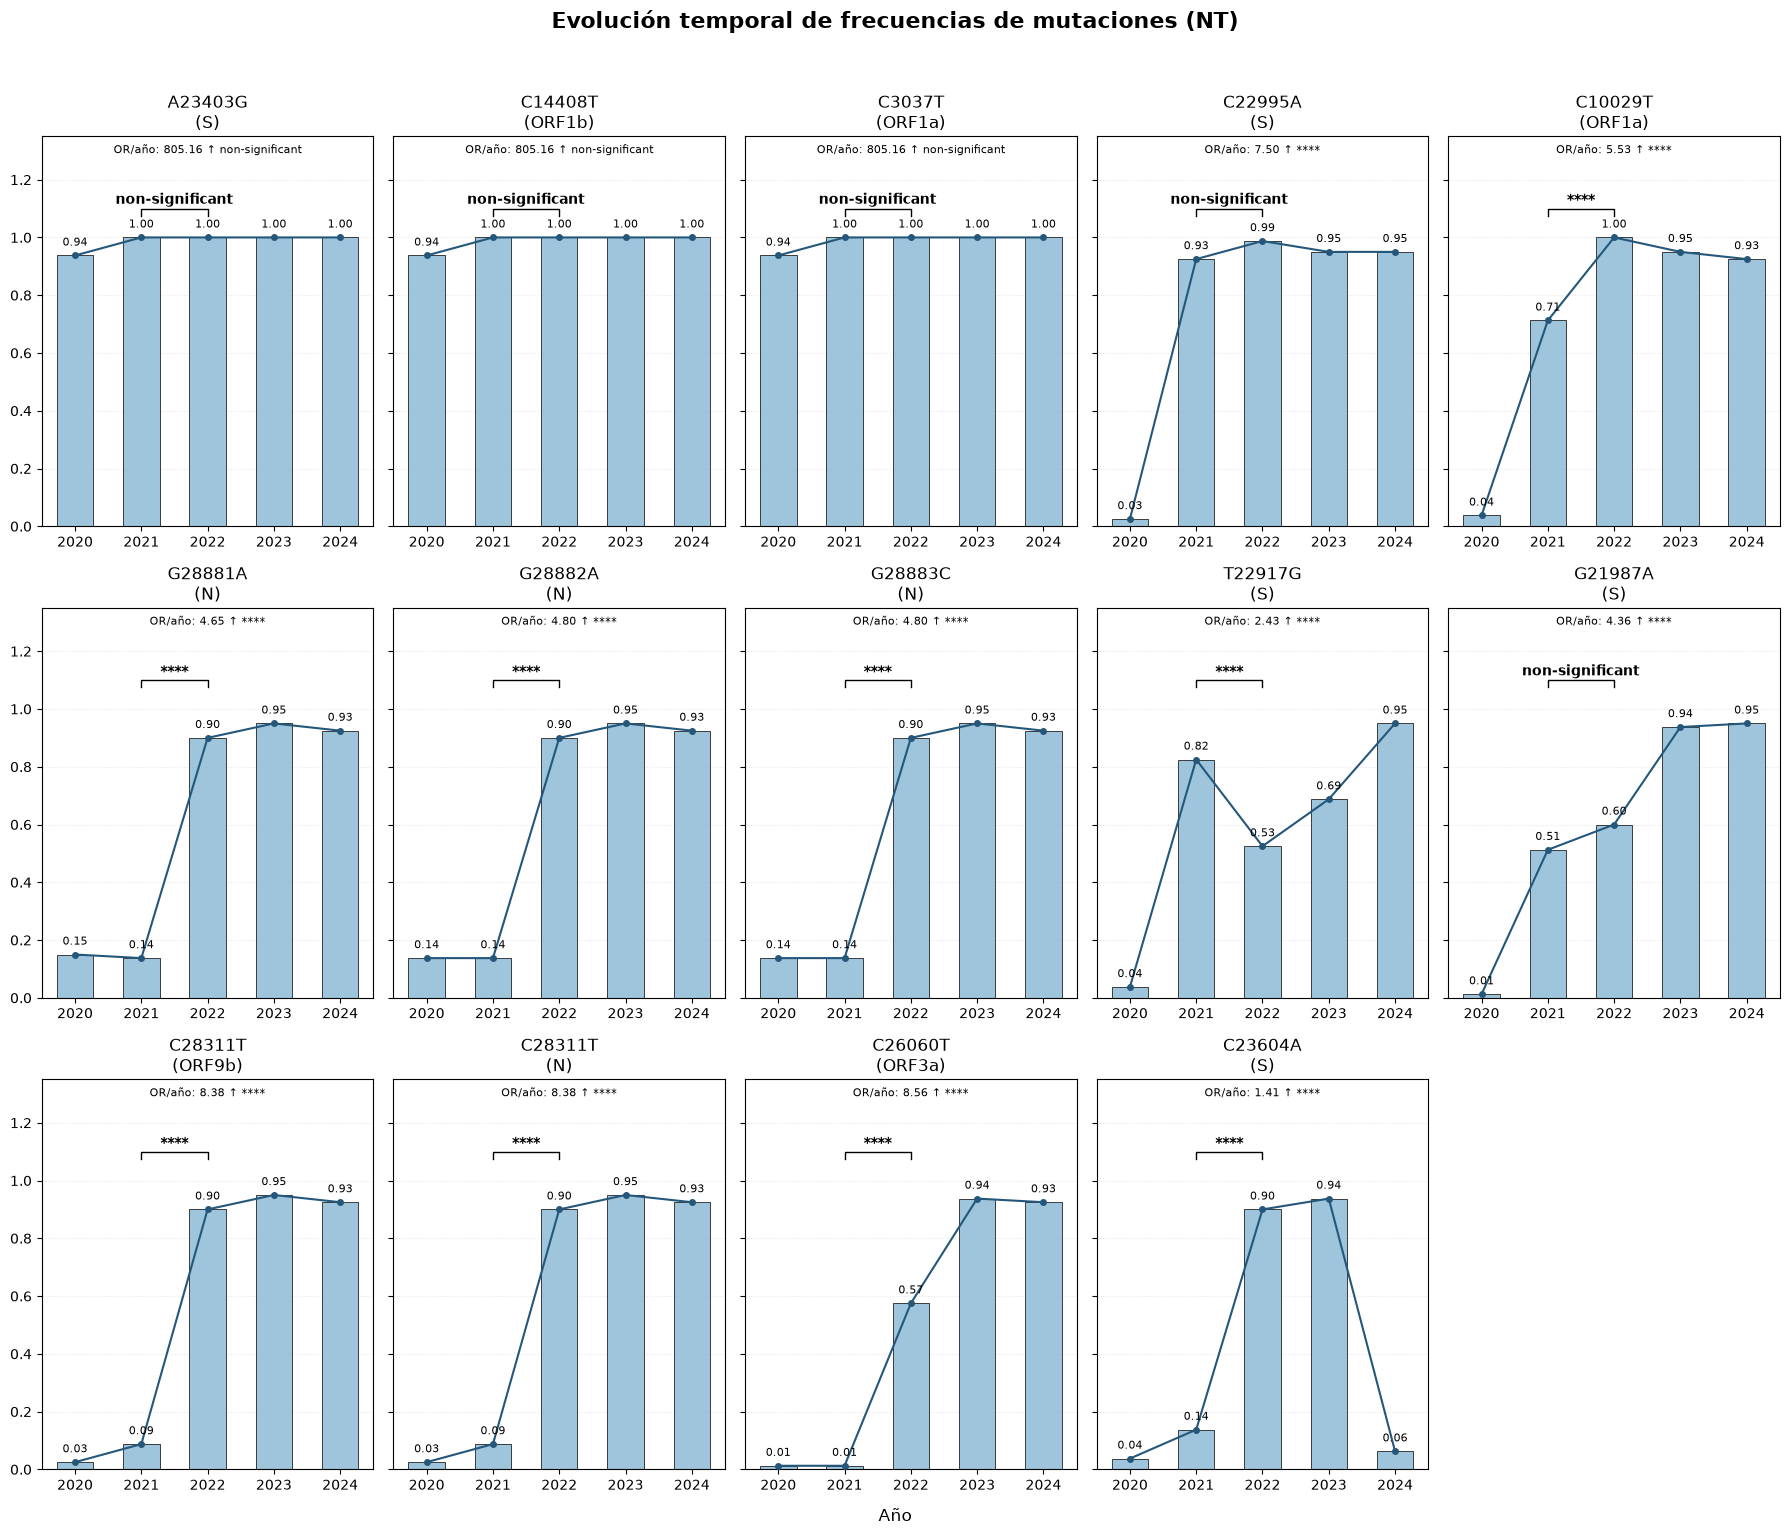

In [ ]:
def save_figure(fig, name):
    """Guarda y muestra una figura."""
    fig.tight_layout()
    fig.savefig(FIG_DIR + "/" + name, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def plot_frequency_heatmap(wide, mutations, level, name):
    """Heatmap de frecuencias anuales."""

    selected = pd.MultiIndex.from_tuples(mutations, names=wide.index.names)
    df = wide.reindex(selected)

    years_available = sorted(c for c in df.columns if isinstance(c, int))
    df = df[years_available]

    labels = [f"{mutation} ({gene})" for mutation, gene in df.index]

    fig, ax = plt.subplots(figsize=(9, 6))

    im = ax.imshow(df.values,aspect="auto",cmap="viridis",vmin=0,vmax=1)

    ax.set_xticks(range(len(years_available)))
    ax.set_xticklabels(years_available)
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)

    ax.set_xlabel("Año")
    ax.set_ylabel("Mutación")
    ax.set_title(f"Frecuencia de mutaciones seleccionadas ({level})",fontweight="bold")

    cbar = fig.colorbar(im, ax=ax)
    cbar.set_label("Frecuencia")

    save_figure(fig, name)


def plot_slope(wide, mutations, level, name):
    """Slope plot de frecuencias entre 2021 y 2022."""

    selected = pd.MultiIndex.from_tuples(mutations, names=wide.index.names)
    df = wide.reindex(selected)
    years_comparison = [2021, 2022]
    fig, ax = plt.subplots(figsize=(11, 7))

    colors = plt.cm.tab20(np.linspace(0, 1, len(df)))

    for color, ((mutation, gene), row) in zip(colors, df.iterrows()):
        frequencies = row[years_comparison]
        ax.plot(years_comparison, frequencies,marker="o", linewidth=1.8,color=color, label=f"{mutation} ({gene})")

    ax.set_xticks(years_comparison)
    ax.set_xlim(2020.9, 2022.3)
    ax.set_ylim(-0.05, 1.05)
    ax.set_ylabel("Frecuencia")
    ax.set_title(f"Cambio de frecuencia 2021-2022 ({level})", fontweight="bold")
    ax.grid(linestyle=":", alpha=0.3)
    ax.legend(title="Mutaciones",bbox_to_anchor=(1.02, 1),loc="upper left",fontsize=8,title_fontsize=9,frameon=True)

    save_figure(fig, name)


def significance_stars(p_value):
    """Convierte un valor p en asteriscos de significancia."""

    if pd.isna(p_value):
        return "NA"
    elif p_value < 0.0001:
        return "****"
    elif p_value < 0.001:
        return "***"
    elif p_value < 0.01:
        return "**"
    elif p_value < 0.05:
        return "*"
    return "non-significant"

def plot_mutation_panels(wide, mutations, df_final, level, name):
    years_available = [y for y in years if y in wide.columns]
    ncols = 5
    nrows = int(np.ceil(len(mutations) / ncols))

    fig, axes = plt.subplots(nrows, ncols, figsize=(18, 5 * nrows), sharey=True)
    axes = np.array(axes).flatten()

    for i, (mutation, gene) in enumerate(mutations):
        ax = axes[i]
        frequencies = wide.loc[(mutation, gene), years_available].astype(float)
        x, y = np.arange(len(years_available)), frequencies.values

        ax.bar(x, y, width=0.55, color="#8DBBD6", edgecolor="black", linewidth=0.6, alpha=0.85)
        ax.plot(x, y, color="#24577A", marker="o", markersize=4, linewidth=1.5, zorder=3)

        for xi, yi in zip(x, y):
            if pd.notna(yi):
                ax.text(xi, yi + 0.025, f"{yi:.2f}", ha="center", va="bottom", fontsize=8)

        result = df_final[(df_final["mutation"] == mutation) & (df_final["gene"] == gene)]

        if not result.empty:
            r = result.iloc[0]
            p_period, p_trend, odds_ratio = r["p_value_periodos"], r["p_value_tendencia"], r["odds_ratio"]

            if 2021 in years_available and 2022 in years_available:
                idx1, idx2 = years_available.index(2021), years_available.index(2022)
                bracket_y, bracket_h = 1.075, 0.025

                ax.plot([idx1, idx1, idx2, idx2],
                        [bracket_y, bracket_y + bracket_h, bracket_y + bracket_h, bracket_y],
                        color="black", linewidth=1)
                ax.text((idx1 + idx2) / 2, bracket_y + bracket_h + 0.005,
                        significance_stars(p_period), ha="center", va="bottom",
                        fontsize=10, fontweight="bold")

            direction = "↑" if r["coef_year"] > 0 else "↓" if r["coef_year"] < 0 else "→"
            trend_text = (f"OR/año: {odds_ratio:.2f} {direction} {significance_stars(p_trend)}"
                          if pd.notna(odds_ratio) else "Tendencia: no estimable")

            ax.text(0.5, 0.98, trend_text, transform=ax.transAxes,ha="center", va="top", fontsize=8)

        ax.set(title=f"{mutation}\n({gene})", xticks=x, xticklabels=years_available, ylim=(0, 1.35))
        ax.grid(axis="y", linestyle=":", alpha=0.3)
        ax.set_axisbelow(True)

    for ax in axes[len(mutations):]:
        fig.delaxes(ax)

    fig.suptitle(f"Evolución temporal de frecuencias de mutaciones ({level})",fontsize=16, fontweight="bold", y=1.02)
    fig.supxlabel("Año", fontsize=12)

    save_figure(fig, name)


# --------------------------------------------------------------------------- Generación de figuras
for wide, mutations, results, level in [(wide_aa, mutaciones_aa, df_aa_final, "AA"),(wide_nt, mutaciones_nt, df_nt_final, "NT")]:
    plot_frequency_heatmap(wide, mutations, level, f"heatmap_frecuencias_{level.lower()}.png")
    plot_slope(wide, mutations, level, f"slope_{level.lower()}.png")
    plot_mutation_panels(wide, mutations, results, level, f"frecuencias_mutaciones_{level.lower()}.png")